# Sample tutorial for ordering sections within an embryo

## This assumes STAIR has been installed, and the spatial data has been downloaded from https://db.cngb.org/stomics/flysta3d-v2/download/

## Here we take the embryo at inferred time 12.94h for example.

In [9]:
import sys
sys.path.append('../../paste3/src')
sys.path.append('../../paste3/src/paste3')
from align import *
from glmpca import *
from helper import *
from model_selection import *
from paste import *
from visualization import *
import anndata as ad
import scanpy as sc
from sampler_full import fused_tlb, full_fgw, eval_pair, fused_upper_bounds
import time
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from scipy.spatial.distance import cdist, pdist

%load_ext autoreload
%autoreload 2
DIR         = "../../Data/FLYSTA/"
adata = sc.read_h5ad(DIR+'12.94h_E10-12h_f_new_final_modified.h5ad')


from sampler_full import fused_tlb, full_fgw, eval_pair, fused_upper_bounds


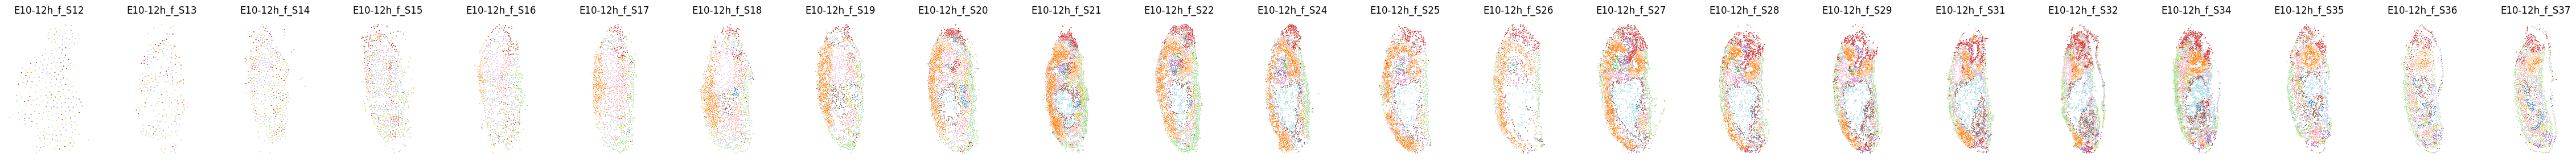

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

CELL_TYPE = 'Annotation_1_cell_type'

slices = (
    adata.obs.groupby("slices", observed=True)["align_z"]
    .median().sort_values().index.tolist()
)
cell_types = adata.obs[CELL_TYPE].astype(str)
types = sorted(cell_types.unique())
cmap = plt.get_cmap("tab20", len(types))
colors = {t: cmap(i) for i, t in enumerate(types)}



fig, axes = plt.subplots(
    1, len(slices),
    figsize=(2 * len(slices), 3),
    squeeze=False,
)

for ax, s in zip(axes.flat, slices):
    mask = (adata.obs["slices"] == s).to_numpy()
    xy = adata.obsm["spatial"][mask]

    ax.scatter(
        xy[:, 0], xy[:, 1],
        c=[colors[t] for t in cell_types[mask]],
        s=2, linewidths=0,
    )
    ax.set_title(str(s), fontsize=12)
    ax.set_aspect("equal")
    ax.axis("off")

for ax in axes.flat[len(slices):]:
    ax.axis("off")

handles = [
    Line2D([], [], marker="o", linestyle="", color=colors[t],
           label=t, markersize=5)
    for t in types
]

plt.tight_layout()
plt.show()

In [12]:

def positive_median(M, name):
    values = M[np.isfinite(M) & (M > 0)]
    if values.size == 0:
        raise ValueError(f"No positive finite distances for {name}")
    return float(np.median(values))



slice_info = adata.obs[["slices", "align_z"]].groupby("slices", observed=True)["align_z"].median().sort_values()

n = len(slice_info)

fused_lb = np.zeros((n, n))
fused_ub = np.zeros((n, n))
fused_ub_q1 = np.zeros((n, n))
fused_ub_q2 = np.zeros((n, n))

slice_ids = adata.obs["slices"].astype(str)

# Order by section name, without consulting align_z.
slices = sorted(slice_ids.unique())
counts = slice_ids.value_counts()

largest = sorted(slices, key=lambda s: (-int(counts[s]), s))[0]
reference = adata[slice_ids == largest].copy()

# Expression scale: positive pairwise expression distances
# WITHIN the largest section, using the original metric helper.
X_ref = to_dense_array(reference.X).double()
M_ref = dissimilarity_metric(
        "euc", reference, reference, X_ref, X_ref
).cpu().numpy()
np.fill_diagonal(M_ref, 0)
feat_scale = positive_median(M_ref, "expression scale")
del M_ref, X_ref

# Spatial scale: positive within-section Euclidean distances.
spatial_ref = np.asarray(reference.obsm["spatial"], dtype=float)
D_ref = cdist(spatial_ref, spatial_ref)
np.fill_diagonal(D_ref, 0)
spatial_scale = positive_median(D_ref, "spatial scale")
del D_ref, spatial_ref, reference

args = dict(
        alpha=0.5,
        exp_metric="euclidean",
        feat_scale=feat_scale,
        spatial_scale=spatial_scale,
        solver="ott",
        # Keep every spot: no section exceeds this cap.
        max_spots=int(counts.max()),
        seed=0,
)

for i in range(n):
    A = adata[adata.obs["slices"] == slices[i]].copy()
    for j in range(i + 1, n):
        B = adata[adata.obs["slices"] == slices[j]].copy()
        val, feat, strc = fused_tlb(A, B, **args)
        fused_lb[i, j] = fused_lb[j, i] = val

        # val = fused_upper_bounds(A, B, alpha=0.5, K=200, exp_metric="euc", spatial_norm="median", feat_norm="none", 
        # solver="ott", max_spots=10000, seed=0)
        # fused_ub[i, j] = fused_ub[j,i] = val['tlb']['val']
        # fused_ub_q1[i, j] = fused_ub_q1[j,i] = val['spatial_stratified']['val']
        # fused_ub_q2[i, j] = fused_ub_q2[j,i] = val['expression_stratified']['val']

        print('pair: '+str(i)+', and '+str(j))

labels = [f"{s} (z={slice_info.loc[s]:.2f})" for s in slices]
fused_lb_df = pd.DataFrame(fused_lb, index=labels, columns=labels)

pair: 0, and 1
pair: 0, and 2
pair: 0, and 3
pair: 0, and 4
pair: 0, and 5
pair: 0, and 6
pair: 0, and 7
pair: 0, and 8
pair: 0, and 9
pair: 0, and 10
pair: 0, and 11
pair: 0, and 12
pair: 0, and 13
pair: 0, and 14
pair: 0, and 15
pair: 0, and 16
pair: 0, and 17
pair: 0, and 18
pair: 0, and 19
pair: 0, and 20
pair: 0, and 21
pair: 0, and 22
pair: 1, and 2
pair: 1, and 3
pair: 1, and 4
pair: 1, and 5
pair: 1, and 6
pair: 1, and 7
pair: 1, and 8
pair: 1, and 9
pair: 1, and 10
pair: 1, and 11
pair: 1, and 12
pair: 1, and 13
pair: 1, and 14
pair: 1, and 15
pair: 1, and 16
pair: 1, and 17
pair: 1, and 18
pair: 1, and 19
pair: 1, and 20
pair: 1, and 21
pair: 1, and 22
pair: 2, and 3
pair: 2, and 4
pair: 2, and 5
pair: 2, and 6
pair: 2, and 7
pair: 2, and 8
pair: 2, and 9
pair: 2, and 10
pair: 2, and 11
pair: 2, and 12
pair: 2, and 13
pair: 2, and 14
pair: 2, and 15
pair: 2, and 16
pair: 2, and 17
pair: 2, and 18
pair: 2, and 19
pair: 2, and 20
pair: 2, and 21
pair: 2, and 22
pair: 3, and 4
p

In [13]:
np.savez(
    "ordering_input.npz",
    fused_lb=fused_lb,
    slices=np.asarray(slices, dtype=str),
    z_true=slice_info.loc[slices].to_numpy(dtype=float),
)

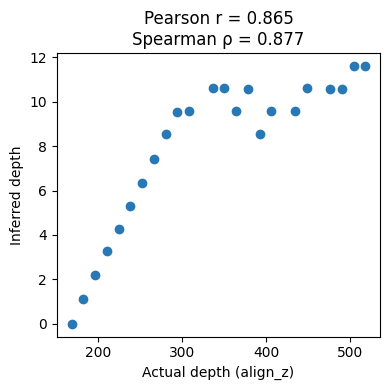

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from STAIR.loc_prediction import sort_slices

data = np.load("ordering_input.npz")
slices = data["slices"].tolist()
z_true = data["z_true"]
D = np.sqrt(data["fused_lb"])
n = len(slices)

# 1D classical MDS.
H = np.eye(n) - np.ones((n, n)) / n
values, vectors = np.linalg.eigh(-0.5 * H @ D**2 @ H)
x = vectors[:, -1] * np.sqrt(values[-1])
D_mds = np.abs(x[:, None] - x[None, :])

# STAIR ordering.
similarity = pd.DataFrame(- D_mds, index=slices, columns=slices)
z_inferred = pd.Series(
    sort_slices(similarity, start=slices[0])
).reindex(slices).to_numpy()

r = pearsonr(z_true, z_inferred).statistic
rho = spearmanr(z_true, z_inferred).statistic

plt.figure(figsize=(4, 4))
plt.scatter(z_true, z_inferred, color="#2878B5")
plt.xlabel("Actual depth (align_z)")
plt.ylabel("Inferred depth")
plt.title(f"Pearson r = {r:.3f}\nSpearman ρ = {rho:.3f}")
plt.tight_layout()
plt.show()
